# P12 — O benchmark de integração refeito com os rótulos novos

**Pergunta.** O P07 escolheu o ComBat medindo a conservação biológica com o
Azimuth automático do Cell Ranger, o único rótulo que havia. Agora há dois
rótulos melhores:

* **a anotação por marcadores canônicos** (P09), por cluster do Leiden sobre o
  ComBat. É curada, mas nasce da integração escolhida, então tende a favorecer
  o ComBat;
* **o tipo L2 do atlas** de Yasumizu et al. (2024), mapeado com o Symphony.
  Não depende de nenhuma integração nossa: é a régua independente.

As 18 execuções do P07 são reavaliadas com cada rótulo: as mesmas integrações,
as mesmas métricas e a mesma agregação (min-max; 0,4 × lote + 0,6 × bio) e a
mesma regra de escolha. scGen e scANVI foram treinados com o Azimuth.
Avaliados agora com outros rótulos, a circularidade do P07 desaparece. Eles
seguem fora da escolha porque impõem um rótulo ao espaço latente, mas a
posição deles diz se a vantagem no P07 vinha do gabarito.

As métricas rodam fora do notebook (`raw/run_benchmark.py metricas --rotulo …`)
e ficam em `metricas__<rótulo>.json` no cache do P07.

**O rótulo isolado.** Nas duas réguas novas, o rótulo "isolado" (o presente no
menor número de bibliotecas) é minúsculo: basófilo (14 células) na anotação e
TcmPHLDA3 (18 células) no atlas. No atlas, nenhuma integração isola esse tipo
(F1 < 0,01 em todas), e o escalonamento min-max transformaria ruído em
diferença de 0 a 1. Por isso a escolha com os rótulos novos usa a agregação
**sem as duas métricas de rótulo isolado**; a do artigo, completa, fica ao
lado. Essa decisão foi tomada ao ver as métricas parciais das primeiras
execuções, antes da classificação final.

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from functions import benchmark as bm, benchplots as bp, config, fmt as F, io, plotting
from functions.issues import IssueLog, show

plotting.apply_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)

NB = "P12_benchmark_integracao_rotulos"
log = IssueLog(NB)
INK = plotting.INK
ROT = {"azimuth": "Azimuth (P07)", "anotacao": "anotação por marcadores (P09)", "atlas_L2": "atlas L2 (independente)"}

## 1. Os rótulos

In [2]:
inp = bm.load_inputs(bm.CACHE / "entradas", full=False)
obs = inp["pre"].obs
rb = pd.read_parquet(io.data_path("P09_anotacao", "rotulos_benchmark", "parquet")).set_index("cell_key").reindex(
    obs["cell_key"].to_numpy())
rotulos = {"azimuth": obs[bm.LABEL].astype(object).to_numpy(), "anotacao": rb["anotacao"].to_numpy(),
           "atlas_L2": rb["atlas_L2"].to_numpy()}
lib = obs[bm.BATCH].astype(str).to_numpy()
desc = []
for k, v in rotulos.items():
    s = pd.Series(v)
    ok = s.notna().to_numpy()
    nb = pd.DataFrame({"r": s[ok].to_numpy(), "b": lib[ok]}).groupby("r")["b"].nunique()
    desc.append({"rótulo": ROT[k], "células com rótulo": int(ok.sum()), "classes": int(s[ok].nunique()),
                 "menor classe": int(s[ok].value_counts().min()),
                 "isoladas (menos bibliotecas)": ", ".join(nb.index[nb == nb.min()]) + f" ({nb.min()} bibl.)"})
desc = pd.DataFrame(desc).set_index("rótulo")
io.save_table(desc, NB, "rotulos", description="Os três rótulos usados nas métricas biológicas")
desc

,células com rótulo,classes,menor classe,isoladas (menos bibliotecas)
rótulo,,,,
Azimuth (P07),33588,7,42,mieloide (12 bibl.)
anotação por marcadores (P09),31350,14,14,basófilo (6 bibl.)
atlas L2 (independente),32340,18,18,TcmPHLDA3 (7 bibl.)


## 2. Scores com cada rótulo

In [3]:
raws, faltam = {}, {}
for k in ROT:
    r, meta = bm.collect(None if k == "azimuth" else k)
    raws[k] = r
    faltam[k] = [x.key for x in bm.RUNS if x.key not in r.index]
print("execuções avaliadas: " + "; ".join(f"{ROT[k]} {len(r)}" for k, r in raws.items()))
if any(faltam.values()):
    print("faltam:", {k: v for k, v in faltam.items() if v})
cols = bm.BATCH_METRICS + bm.BIO_METRICS
comuns = sorted(set.intersection(*[set(r.index) for r in raws.values()]), key=[x.key for x in bm.RUNS].index)
ret = bm.stimulus_retention(raws["azimuth"])
ISO = ("Isolated label F1", "Isolated label silhouette")
summ, esc, choice, summ_art, choice_art = {}, {}, {}, {}, {}
for k, r in raws.items():
    r = r.loc[comuns]
    summ_art[k] = bm.aggregate(r)                                    # a do artigo, completa
    choice_art[k] = bm.choose(summ_art[k], ret)
    summ[k] = summ_art[k] if k == "azimuth" else bm.aggregate(r, drop=ISO)   # principal
    esc[k] = bm.minmax(r, cols)
    if k != "azimuth":
        esc[k][list(ISO)] = np.nan
    choice[k] = bm.choose(summ[k], ret)
iso_vals = pd.DataFrame({ROT[k]: raws[k].loc[comuns, "Isolated label F1"] for k in ROT})
io.save_table(iso_vals, NB, "isolated_label_f1", description="Isolated label F1 com cada rótulo (o rótulo isolado de cada régua)")
tab = pd.concat({ROT[k]: s for k, s in summ.items()}, axis=1)
tab.index = [bm.RUN[x].label + ("" if bm.RUN[x].scaled is None else f" · {bm.RUN[x].scaling}") for x in tab.index]
io.save_table(tab, NB, "resumo_por_rotulo", description="Scores do artigo com cada rótulo (min-max; 0,4 lote + 0,6 bio)")
escolhas = pd.DataFrame({ROT[k]: {"escolhido": bm.RUN[c["escolhido"]].label + f" ({c['escolhido']})",
                                  "escolhido (agregação completa do artigo)": choice_art[k]["escolhido"],
                                  "maior geral elegível": c["melhor_geral_elegivel"],
                                  "empatados": ", ".join(c["empatados"]), "vetados": ", ".join(c["vetados"])}
                         for k, c in choice.items()}).T
io.save_table(escolhas, NB, "escolhas", description="Método escolhido pela regra do P07 com cada rótulo")
escolhas

execuções avaliadas: Azimuth (P07) 18; anotação por marcadores (P09) 18; atlas L2 (independente) 18


,escolhido,escolhido (agregação completa do artigo),maior geral elegível,empatados,vetados
Azimuth (P07),ComBat (combat_esc),combat_esc,combat_esc,combat_esc,"bbknn_esc, bbknn"
anotação por marcadores (P09),Seurat v5 RPCA (seurat_rpca),seurat_rpca,seurat_rpca,seurat_rpca,"bbknn_esc, bbknn"
atlas L2 (independente),Seurat v5 RPCA (seurat_rpca),combat_esc,harmony_esc,"harmony_esc, seurat_rpca","bbknn_esc, bbknn"


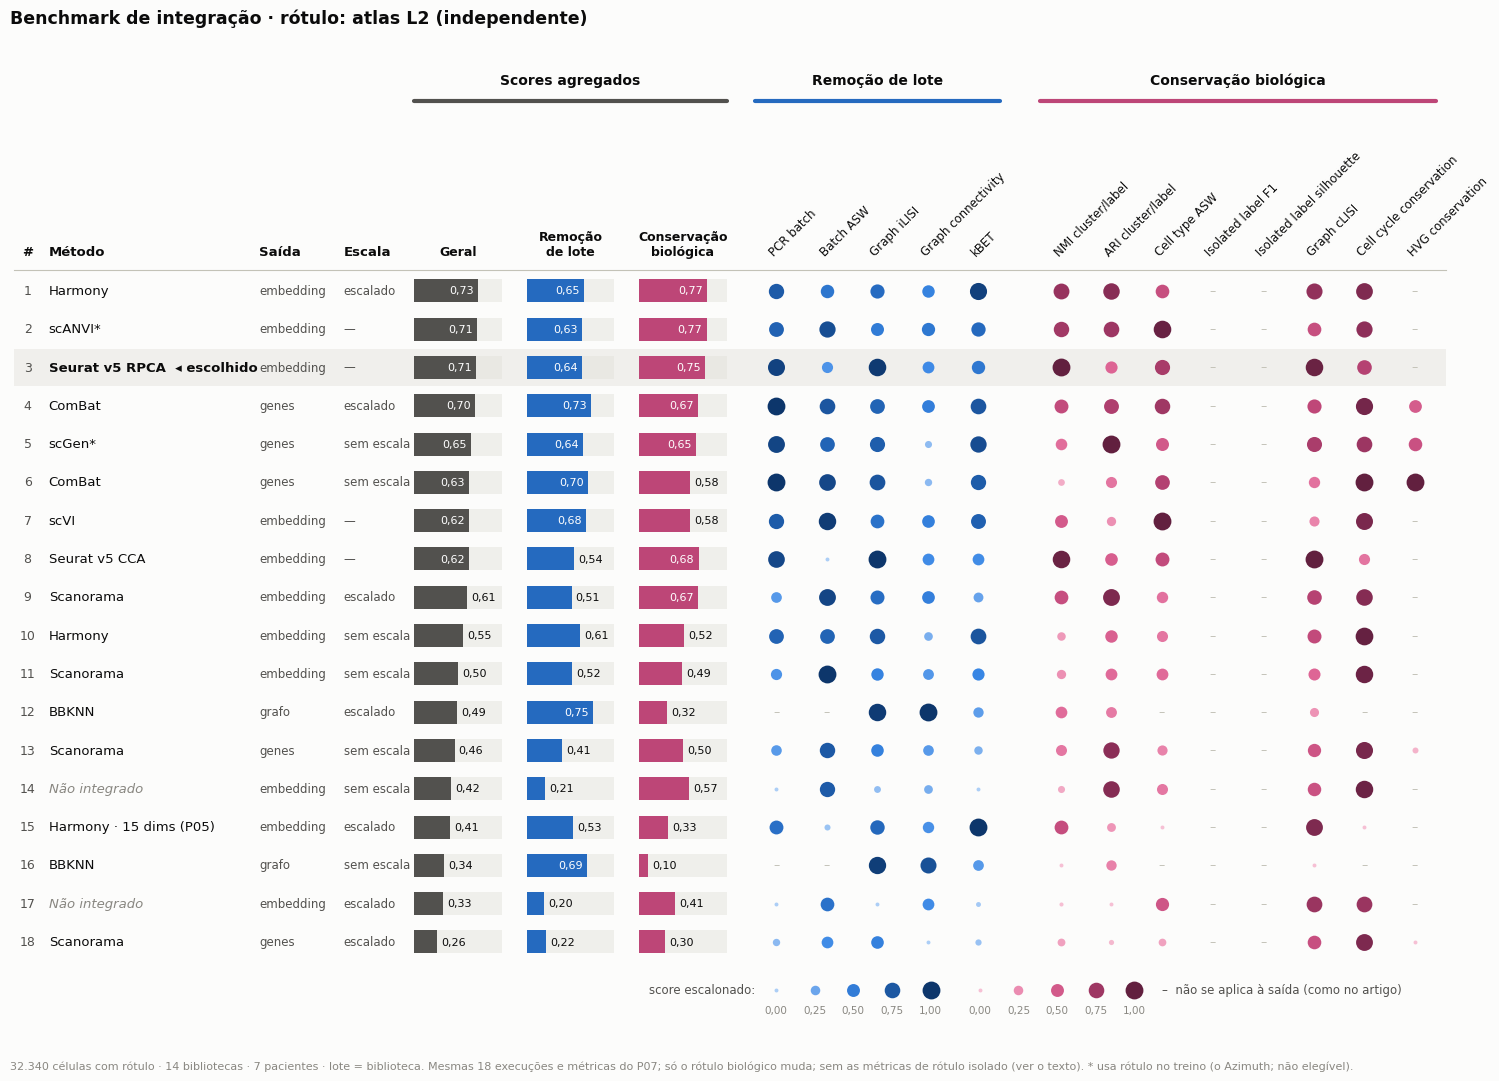

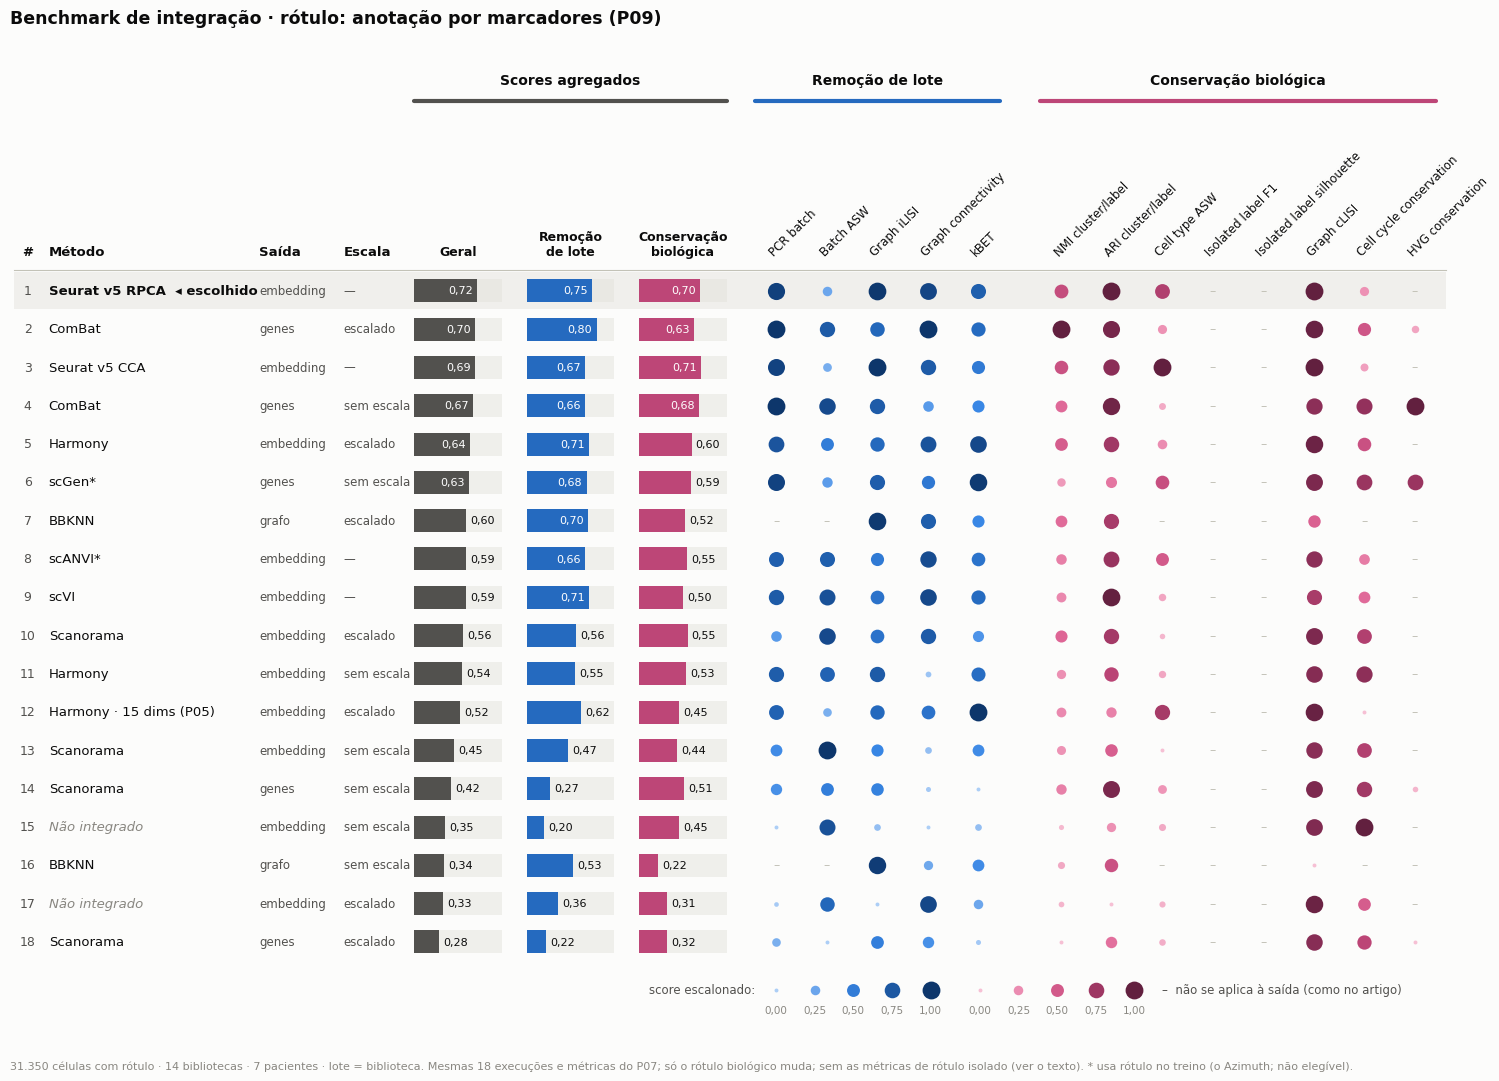

In [4]:
for k in ("atlas_L2", "anotacao"):
    fig = bp.results_table(summ[k], esc[k], chosen=choice[k]["escolhido"],
                           title=f"Benchmark de integração · rótulo: {ROT[k]}",
                           note=f"{F.n(int(pd.notna(rotulos[k]).sum()))} células com rótulo · {plotting.N_DESIGN} · lote = biblioteca. "
                                "Mesmas 18 execuções e métricas do P07; só o rótulo biológico muda; sem as métricas de rótulo "
                                "isolado (ver o texto). * usa rótulo no treino (o Azimuth; não elegível).")
    plotting.savefig(fig, NB, f"tabela_resumo_{k}", description=f"Tabela-resumo do benchmark com o rótulo {ROT[k]}",
                     data=summ[k].join(esc[k]).reset_index(), data_index=False)
    plt.show()

## 3. A classificação muda com o rótulo?

Posição de cada execução elegível sob cada rótulo (1 = melhor) e a
correlação de Spearman entre as classificações.

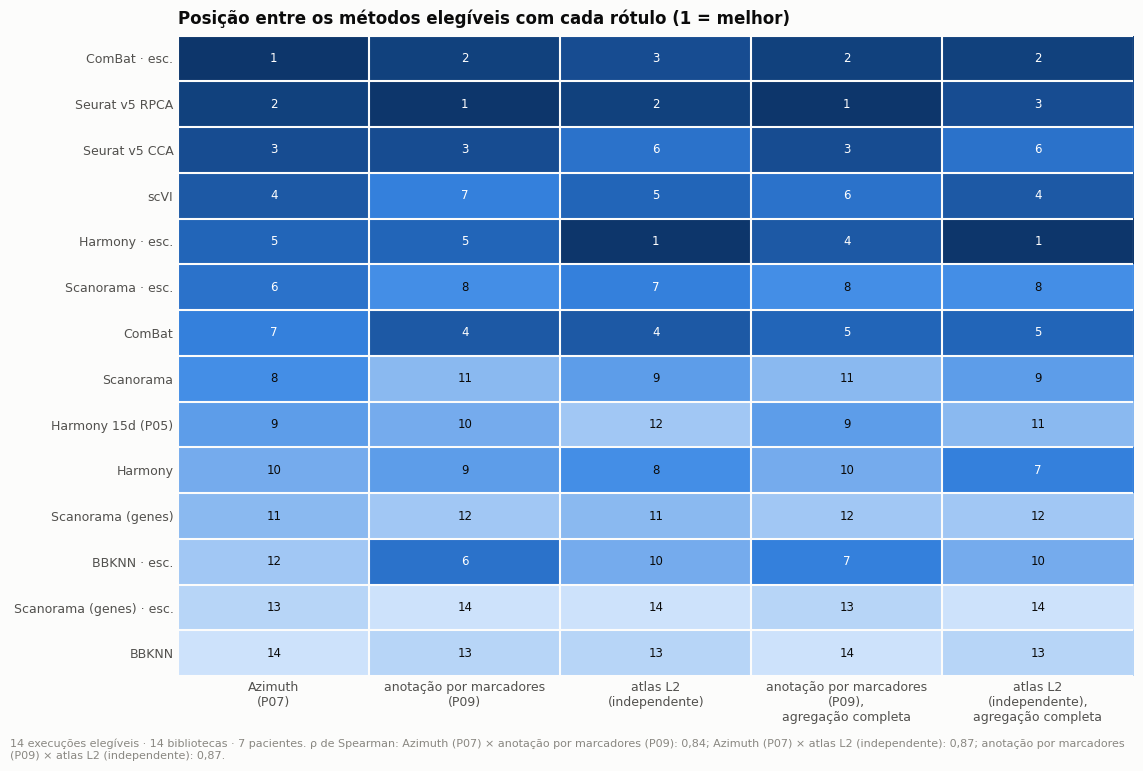

,Azimuth (P07),anotação por marcadores (P09),atlas L2 (independente)
key,,,
Harmony (harmony_esc),7.0,5.0,1.0
scANVI* (scanvi),2.0,8.0,2.0
Seurat v5 RPCA (seurat_rpca),4.0,1.0,3.0
ComBat (combat_esc),3.0,2.0,4.0
scGen* (scgen),1.0,6.0,5.0
ComBat (combat),9.0,4.0,6.0
scVI (scvi),6.0,9.0,7.0
Seurat v5 CCA (seurat_cca),5.0,3.0,8.0
Scanorama (scanorama_esc_emb),8.0,10.0,9.0


In [5]:
eleg = [x for x in comuns if not bm.RUN[x].uses_labels and not bm.RUN[x].method.startswith("Não integrado")]
pos = pd.DataFrame({ROT[k]: summ[k].loc[eleg, "Overall score"].rank(ascending=False, method="min") for k in ROT})
for k in ("anotacao", "atlas_L2"):
    pos[f"{ROT[k]}, agregação completa"] = summ_art[k].loc[eleg, "Overall score"].rank(ascending=False, method="min")
pos = pos.loc[pos.iloc[:, 0].sort_values().index]
base = [ROT[k] for k in ROT]
rhos = {f"{a} × {b}": float(stats.spearmanr(pos[a], pos[b]).statistic)
        for i, a in enumerate(base) for b in base[i + 1:]}
todos = pd.DataFrame({ROT[k]: summ[k]["Overall score"].rank(ascending=False, method="min") for k in ROT})
io.save_table(pos.rename(index=lambda x: bm.RUN[x].label + f" ({x})"), NB, "posicoes",
              description="Posição dos elegíveis sob cada rótulo")
io.save_table(todos.rename(index=lambda x: bm.RUN[x].label + f" ({x})"), NB, "posicoes_todas",
              description="Posição de todas as execuções (inclusive scGen e scANVI) sob cada rótulo")
fig, ax = plt.subplots(figsize=(11.5, 0.36 * len(pos) + 2.4))
m = len(pos) + 1 - pos
m.index = [bp._short(x) for x in pos.index]
m.columns = [c.replace(" (", "\n(").replace(", ", ",\n") for c in pos.columns]
plotting.heatmap(ax, m, vmin=1, vmax=len(pos), cbar=False, xrotation=0)
for i in range(pos.shape[0]):
    for j in range(pos.shape[1]):
        ax.text(j, i, str(int(pos.iat[i, j])), ha="center", va="center", fontsize=8.5,
                color="white" if m.iat[i, j] / len(pos) > 0.55 else INK["primary"])
ax.set_title("Posição entre os métodos elegíveis com cada rótulo (1 = melhor)")
plotting.note(fig, f"{len(pos)} execuções elegíveis · {plotting.N_DESIGN}. ρ de Spearman: "
                   + "; ".join(f"{k}: {F.f(v, 2)}" for k, v in rhos.items()) + ".", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "posicoes", description="Posição dos elegíveis sob cada rótulo",
                 data=pos.reset_index(), data_index=False)
plt.show()
todos.rename(index=lambda x: bm.RUN[x].label + f" ({x})").sort_values(ROT["atlas_L2"])

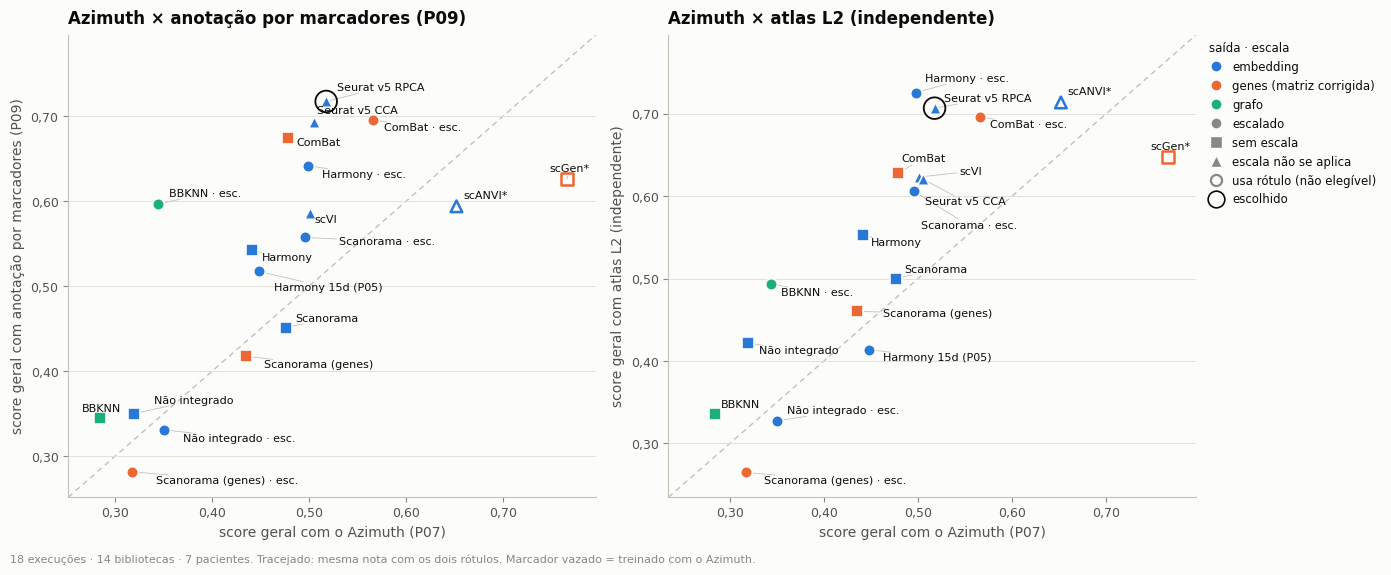

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
for ax, k in zip(axes, ("anotacao", "atlas_L2")):
    x, y = summ["azimuth"]["Overall score"], summ[k]["Overall score"]
    bp._scatter_runs(ax, x, y, None, chosen=choice[k]["escolhido"])
    lo, hi = min(x.min(), y.min()) - 0.03, max(x.max(), y.max()) + 0.03
    ax.plot([lo, hi], [lo, hi], color=INK["axis"], lw=1, ls=(0, (4, 3)), zorder=0)
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_xlabel("score geral com o Azimuth (P07)")
    ax.set_ylabel(f"score geral com {ROT[k]}")
    plotting.decimals(ax, "x", 2)
    plotting.decimals(ax, "y", 2)
    ax.set_title(f"Azimuth × {ROT[k]}", loc="left")
bp._scatter_legend(fig, axes[-1], size_note=False)
plotting.note(fig, f"{len(comuns)} execuções · {plotting.N_DESIGN}. Tracejado: mesma nota com os dois rótulos. Marcador vazado = "
                   "treinado com o Azimuth.", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "azimuth_x_novos", description="Score geral com o Azimuth × com os rótulos novos",
                 data=pd.concat({k: s["Overall score"] for k, s in summ.items()}, axis=1).reset_index(), data_index=False)
plt.show()

## Problemas encontrados

In [7]:
c_atl = choice["atlas_L2"]["escolhido"]
c_ann = choice["anotacao"]["escolhido"]
sg = {k: int(todos.loc["scgen", ROT[k]]) for k in ROT}
sa = {k: int(todos.loc["scanvi", ROT[k]]) for k in ROT}
pos_combat = pos.loc["combat_esc"]
top3 = bool((pos_combat <= 3).all())
gap = float(summ["atlas_L2"].loc[eleg, "Overall score"].max() - summ["atlas_L2"].loc["combat_esc", "Overall score"])
log.add("MINOR" if top3 else "MAJOR", "escolha com rótulos melhores",
        "com a anotação e com o atlas, a regra do P07 deixa de apontar um único método",
        evidence=f"escolhido: Azimuth → ComBat; anotação → {bm.RUN[c_ann].label}; atlas → {bm.RUN[c_atl].label} "
                 f"(agregação completa do artigo no atlas: {bm.RUN[choice_art['atlas_L2']['escolhido']].label}); posições do "
                 "ComBat entre os elegíveis: " + ", ".join(str(int(v)) for v in pos_combat) + f"; no atlas, a "
                 f"{F.f(gap, 3)} do primeiro",
        impact="ComBat, Seurat RPCA e Harmony escalado (50 dimensões) formam um grupo de cima, a poucos centésimos um do "
               "outro; a vantagem do ComBat no P07 não é robusta à régua" + ("" if top3 else ", e ele sai do grupo"),
        recommendation="manter o ComBat: fica entre os 3 primeiros em todas as variantes e é o único do grupo que devolve "
                       "a matriz de genes corrigida, de que a NMF do P10 precisa. Em análises só por embedding ou grafo, o "
                       "Seurat RPCA é equivalente" if top3 else "rever a integração do P08")
p15 = pos.loc["harmony_esc_15d"]
log.add("INFO", "Harmony do P05", "[RESULTADO] a integração antiga (Harmony, 15 dimensões) fica para trás com qualquer régua",
        evidence="posições entre os elegíveis: " + ", ".join(str(int(v)) for v in p15),
        impact="a troca feita no P07 se sustenta com rótulos independentes",
        recommendation="nenhuma")
log.add("MINOR", "scGen e scANVI com outros rótulos", "a posição dos métodos treinados com o Azimuth muda quando a régua muda",
        evidence="scGen: " + ", ".join(f"{ROT[k]} {v}º" for k, v in sg.items()) + "; scANVI: "
                 + ", ".join(f"{ROT[k]} {v}º" for k, v in sa.items()),
        impact="o scGen cai do 1º lugar (Azimuth, o rótulo com que foi treinado) para o meio da tabela: a vantagem no "
               "P07 vinha do gabarito; o scANVI segue no alto com o atlas",
        recommendation="nenhuma; seguem fora da escolha (impõem o Azimuth ao espaço latente)")
log.add("MINOR", "anotação e ComBat", "a anotação do P09 nasceu dos clusters sobre o ComBat",
        evidence=f"com a anotação, o escolhido é {bm.RUN[c_ann].label}",
        impact="a régua da anotação tende a favorecer o ComBat; a do atlas não",
        recommendation="usar o atlas como régua principal desta comparação")
issues = log.save()
print(log.summary().to_string())
show(issues)

severity
CRITICAL    0
MAJOR       0
MINOR       3
INFO        1


severity,location,problem,evidence,impact,recommendation
MINOR,escolha com rótulos melhores,"com a anotação e com o atlas, a regra do P07 deixa de apontar um único método","escolhido: Azimuth → ComBat; anotação → Seurat v5 RPCA; atlas → Seurat v5 RPCA (agregação completa do artigo no atlas: ComBat); posições do ComBat entre os elegíveis: 1, 2, 3, 2, 2; no atlas, a 0,030 do primeiro","ComBat, Seurat RPCA e Harmony escalado (50 dimensões) formam um grupo de cima, a poucos centésimos um do outro; a vantagem do ComBat no P07 não é robusta à régua","manter o ComBat: fica entre os 3 primeiros em todas as variantes e é o único do grupo que devolve a matriz de genes corrigida, de que a NMF do P10 precisa. Em análises só por embedding ou grafo, o Seurat RPCA é equivalente"
MINOR,scGen e scANVI com outros rótulos,a posição dos métodos treinados com o Azimuth muda quando a régua muda,"scGen: Azimuth (P07) 1º, anotação por marcadores (P09) 6º, atlas L2 (independente) 5º; scANVI: Azimuth (P07) 2º, anotação por marcadores (P09) 8º, atlas L2 (independente) 2º","o scGen cai do 1º lugar (Azimuth, o rótulo com que foi treinado) para o meio da tabela: a vantagem no P07 vinha do gabarito; o scANVI segue no alto com o atlas",nenhuma; seguem fora da escolha (impõem o Azimuth ao espaço latente)
MINOR,anotação e ComBat,a anotação do P09 nasceu dos clusters sobre o ComBat,"com a anotação, o escolhido é Seurat v5 RPCA",a régua da anotação tende a favorecer o ComBat; a do atlas não,usar o atlas como régua principal desta comparação
INFO,Harmony do P05,"[RESULTADO] a integração antiga (Harmony, 15 dimensões) fica para trás com qualquer régua","posições entre os elegíveis: 9, 10, 12, 9, 11",a troca feita no P07 se sustenta com rótulos independentes,nenhuma


## Conclusão

**Com rótulos melhores, o grupo de cima é o mesmo, mas a ordem interna
muda.** ComBat escalado, Seurat RPCA e Harmony escalado (50 dimensões) ficam a
poucos centésimos um do outro. Com o atlas, a régua independente, a ordem é
Harmony 0,726, RPCA 0,707 e ComBat 0,696. A regra do P07 escolhe o RPCA com a
anotação (por 0,022) e também com o atlas: Harmony e RPCA empatam, e o RPCA
preserva mais o estímulo. Com a agregação completa do artigo no atlas, volta a
escolher o ComBat. As classificações das três réguas se correlacionam
(ρ 0,84–0,87).

**O ComBat continua sendo a integração do pipeline:**

* fica entre os 3 primeiros elegíveis nas 5 variantes (1º, 2º, 3º, 2º, 2º);
* é o único do grupo de cima que devolve a matriz de genes corrigida, e a NMF
  do P10 precisa dela (o Seurat v5 e o Harmony devolvem só um embedding).

Para análises só por embedding ou grafo, o Seurat RPCA é uma alternativa
equivalente.

**O que os rótulos novos confirmam:**

* a integração antiga (Harmony com 15 dimensões, P05) fica entre o 9º e o 12º
  lugar com qualquer régua;
* a vantagem do scGen no P07 vinha do rótulo com que foi treinado: ele cai do
  1º para o 6º (anotação) e o 5º (atlas). O scANVI segue no alto com o atlas
  (2º).

**Limite.** O rótulo isolado é minúsculo nas duas réguas novas (14 e 18
células), e a agregação principal o deixa de fora. A decisão foi tomada ao
ver as métricas parciais; a agregação completa do artigo aparece ao lado, e
ela favorece o ComBat.